,Seed,Regions,SC_edges
0,12,32,96
1,22,32,122
2,32,31,118
3,42,30,151
4,52,36,120


Pearson        Spearman       
          mean    std     mean    std
Stage                                
stage1   0.798  0.150    0.791  0.143
stage2   0.720  0.143    0.720  0.131
stage3   0.602  0.120    0.611  0.122

Sign_match        Chance       
             mean    std   mean    std
Stage                                 
stage1      0.855  0.098  0.531  0.021
stage2      0.831  0.056  0.528  0.016
stage3      0.790  0.047  0.527  0.014

Subset_A        Subset_B        Jaccard       
                       mean    std     mean    std    mean    std
Transition Density                                               
II-I       0.025      0.400  0.383    0.211  0.231   0.133  0.183
           0.050      0.496  0.169    0.391  0.213   0.250  0.276
           0.100      0.579  0.216    0.673  0.099   0.432  0.144
           0.150      0.713  0.075    0.708  0.101   0.541  0.113
III-I      0.025      0.211  0.140    0.468  0.198   0.200  0.447
           0.050      0.531  0.132    0.462  0.155   0.214  0.143
           0.100      0.590  0.097    0.629  0.140   0.397  0.165
           0.150      0.683  0.091    0.674  0.101   0.457  0.143
III-II     0.025      0.452  0.391    0.331  0.260   0.400  0.548
           0.050      0.631  0.223    0.401  0.191   0.232  0.187
           0.100      0.627  0.150    0.567  0.162   0.365  0.182
           0.150      0.664  0.080    0.628  0.181   0.500  0.135

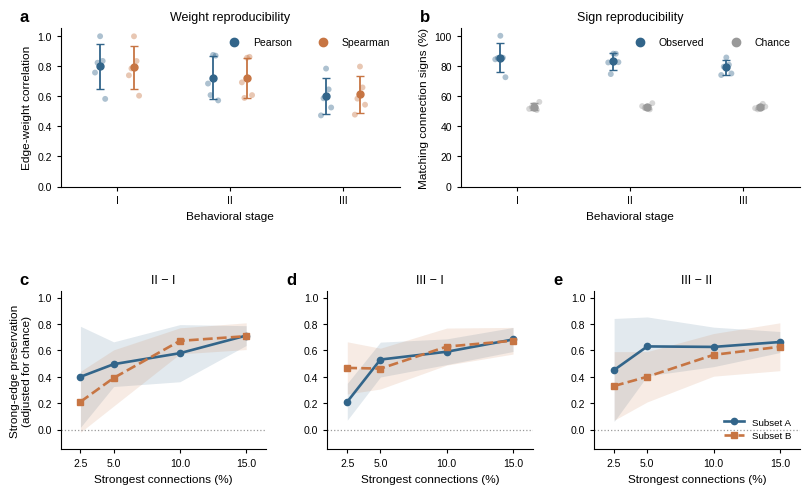

In [1]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from matplotlib.lines import Line2D

seeds = [12,22,32,42,52]
stages = ['stage1','stage2','stage3']
configs = dict(zip(stages,['bs32_dp0.1_sw1.0','bs32_dp0.1_sw1.0','bs32_dp0.1_sw0.5']))
trans = {'II-I':('stage2','stage1'),'III-I':('stage3','stage1'),'III-II':('stage3','stage2')}
densities = [.025,.05,.10,.15]
pkl = '../brain_region_wo_layer_{s}_subset{g}_seed{seed}.pkl'
graph = './result_split_seed{seed}/{s}/subset{g}/tuning/{c}/dynamic_full_graphs.npy'
BLUE, ORANGE, GRAY = '#32658A','#C77543','#999999'

sc = pd.read_excel('../SEU_net_wo_corticalLayers.xlsx',header=1,index_col=1).iloc[:,1:]
sc.index = sc.index.astype(str).str.strip()
sc.columns = sc.columns.astype(str).str.strip()

def corr(a,b):
    return np.corrcoef(a,b)[0,1] if len(a)>1 and a.std() and b.std() else np.nan

def top(x,k):
    return set(np.argsort(-np.abs(x),kind='stable')[:k])

weights, signs, preservation, coverage = [],[],[],[]

for seed in seeds:
    orders = {}
    for s in stages:
        for g in 'AB':
            with open(pkl.format(s=s,g=g,seed=seed),'rb') as f:
                orders[s,g] = [str(r).strip() for r in pickle.load(f)]

    common = set.intersection(*(set(v) for v in orders.values()))
    regions = [r for r in sc.index if r in common and r in sc.columns]
    S = sc.loc[regions,regions].to_numpy(float)
    mask = np.isfinite(S)&(S!=0)
    np.fill_diagonal(mask,False)
    N = int(mask.sum())
    if N<2: raise ValueError(f'Seed {seed}: insufficient edges')
    coverage.append([seed,len(regions),N])

    fc = {}
    for (s,g),order in orders.items():
        path = graph.format(seed=seed,s=s,g=g,c=configs[s])
        x = np.load(path,mmap_mode='r')
        x = x.mean(0) if x.ndim==3 else np.asarray(x)
        if x.shape!=(len(order),len(order)):
            raise ValueError(f'Shape mismatch: {path}')

        csv = f'./result_split_seed{seed}/{s}/subset{g}/df_scaled.csv'
        if os.path.exists(csv):
            actual = pd.read_csv(csv).iloc[:,0].astype(str).str.strip().tolist()
            if actual!=order: raise ValueError(f'Region order mismatch: {csv}')

        idx = {r:i for i,r in enumerate(order)}
        ids = [idx[r] for r in regions]
        fc[s,g] = x[np.ix_(ids,ids)][mask]
        if not np.isfinite(fc[s,g]).all():
            raise ValueError(f'Non-finite FC: {seed}, {s}, {g}')

    for s in stages:
        a,b = fc[s,'A'],fc[s,'B']
        weights.append([seed,s,corr(a,b),spearmanr(a,b).statistic])

        valid = (a!=0)&(b!=0)
        sa,sb = np.sign(a[valid]),np.sign(b[valid])
        match = np.mean(sa==sb) if len(sa) else np.nan
        chance = sum(np.mean(sa==v)*np.mean(sb==v) for v in [-1,1]) if len(sa) else np.nan
        signs.append([seed,s,match,chance])

    for name,(later,earlier) in trans.items():
        for density in densities:
            k = max(1,int(np.ceil(N*density)))
            chance = k/N
            retained = {g:top(fc[earlier,g],k)&top(fc[later,g],k) for g in 'AB'}
            a,b = [(len(retained[g])/k-chance)/(1-chance) for g in 'AB']
            u = retained['A']|retained['B']
            jac = len(retained['A']&retained['B'])/len(u) if u else np.nan
            preservation.append([seed,name,density,a,b,jac])

weight_df = pd.DataFrame(weights,columns=['Seed','Stage','Pearson','Spearman'])
sign_df = pd.DataFrame(signs,columns=['Seed','Stage','Sign_match','Chance'])
pres_df = pd.DataFrame(preservation,columns=['Seed','Transition','Density','Subset_A','Subset_B','Jaccard'])

display(pd.DataFrame(coverage,columns=['Seed','Regions','SC_edges']))
display(weight_df.groupby('Stage')[['Pearson','Spearman']].agg(['mean','std']).round(3))
display(sign_df.groupby('Stage')[['Sign_match','Chance']].agg(['mean','std']).round(3))
display(pres_df.groupby(['Transition','Density'])[['Subset_A','Subset_B','Jaccard']].agg(['mean','std']).round(3))

plt.rcParams.update({
    'font.family':'sans-serif',
    'font.sans-serif':['Arial','Liberation Sans','DejaVu Sans'],
    'font.size':8,'axes.labelsize':8.5,'axes.titlesize':9,
    'xtick.labelsize':7.5,'ytick.labelsize':7.5,
    'axes.linewidth':.8,'xtick.direction':'out','ytick.direction':'out',
    'pdf.fonttype':42,'ps.fonttype':42,
    'pdf.use14corefonts':False,'text.usetex':False
})

fig = plt.figure(figsize=(8.4,5.4))
gs = fig.add_gridspec(2,6,left=.10,right=.98,top=.91,bottom=.13,
                      hspace=.66,wspace=.85)
axA,axB = fig.add_subplot(gs[0,:3]),fig.add_subplot(gs[0,3:])
axC = [fig.add_subplot(gs[1,i*2:i*2+2]) for i in range(3)]

def clean(ax):
    ax.spines[['top','right']].set_visible(False)
    ax.tick_params(length=3,width=.8)
    ax.grid(False)

def plot_stage(ax,df,metrics,ylabel,title,scale=1):
    jitter = np.linspace(-.045,.045,len(seeds))
    for j,(metric,color,label) in enumerate(metrics):
        for i,s in enumerate(stages):
            y = df[df.Stage==s].set_index('Seed').loc[seeds,metric].to_numpy()*scale
            x = i+(-.15 if j==0 else .15)
            ax.scatter(x+jitter,y,s=18,color=color,alpha=.4,edgecolors='none')
            ax.errorbar(x,y.mean(),yerr=y.std(ddof=1),fmt='o',
                        ms=5,lw=1.3,capsize=3,color=color,zorder=5)
    ax.set(xticks=range(3),xticklabels=['I','II','III'],
           xlim=(-.5,2.5),ylim=(0,1.05*scale),
           xlabel='Behavioral stage',ylabel=ylabel,title=title)
    ax.legend([Line2D([],[],marker='o',ls='',color=c) for _,c,_ in metrics],
              [label for _,_,label in metrics],
              frameon=False,fontsize=7.5,ncol=2,loc='upper right')
    clean(ax)

plot_stage(axA,weight_df,
           [('Pearson',BLUE,'Pearson'),('Spearman',ORANGE,'Spearman')],
           'Edge-weight correlation','Weight reproducibility')

plot_stage(axB,sign_df,
           [('Sign_match',BLUE,'Observed'),('Chance',GRAY,'Chance')],
           'Matching connection signs (%)','Sign reproducibility',100)

for ax,(name,_) in zip(axC,trans.items()):
    d = pres_df[pres_df.Transition==name]
    for metric,color,marker,ls,label in [
        ('Subset_A',BLUE,'o','-','Subset A'),
        ('Subset_B',ORANGE,'s','--','Subset B')
    ]:
        stat = d.groupby('Density')[metric].agg(['mean','std']).reindex(densities)
        x = stat.index.to_numpy()*100
        y,sd = stat['mean'].to_numpy(),stat['std'].to_numpy()
        ax.fill_between(x,y-sd,y+sd,color=color,alpha=.14,lw=0)
        ax.plot(x,y,ls=ls,marker=marker,color=color,lw=1.9,ms=4.5,label=label)
    ax.axhline(0,ls=':',color=GRAY,lw=.9)
    ax.set(xticks=np.array(densities)*100,xlim=(1,16.5),
           ylim=(-.15,1.05),xlabel='Strongest connections (%)',
           title=name.replace('-',' − '))
    clean(ax)

axC[0].set_ylabel('Strong-edge preservation\n(adjusted for chance)')
axC[2].legend(frameon=False,fontsize=7,loc='lower right')

for ax,label,x in zip([axA,axB,*axC],'abcde',[-.12,-.12,-.20,-.20,-.20]):
    ax.text(x,1.12,label,transform=ax.transAxes,
            fontsize=12,fontweight='bold',va='top')

fig.savefig('NEXUS_split_half_reproducibility.pdf',
            bbox_inches='tight',pad_inches=.08,facecolor='white')
plt.show()

,Seed,Regions,SC_edges
0,12,32,96
1,22,32,122
2,32,31,118
3,42,30,151
4,52,36,120


Sign_agreement        Chance_sign         \
                             mean    std        mean    std   
Transition Top_pct                                            
II-I       10               0.488  0.125       0.299  0.027   
           20               0.536  0.171       0.298  0.027   
           30               0.499  0.171       0.298  0.028   
III-I      10               0.581  0.117       0.322  0.038   
           20               0.524  0.097       0.323  0.046   
           30               0.490  0.071       0.322  0.044   
III-II     10               0.526  0.093       0.324  0.022   
           20               0.485  0.071       0.329  0.024   
           30               0.473  0.078       0.326  0.022   

                   Direction_consistency        Relative_magnitude         \
                                    mean    std               mean    std   
Transition Top_pct                                                          
II-I       10                      0.265  0.200              2.418  1.011   
           20                      0.333  0.267              2.040  0.534   
           30                      0.280  0.263              2.999  1.549   
III-I      10                      0.388  0.167              2.957  1.661   
           20                      0.297  0.149              2.585  1.048   
           30                      0.246  0.118              2.968  1.584   
III-II     10                      0.299  0.139              2.883  0.838   
           20                      0.231  0.114              2.783  0.843   
           30                      0.218  0.120              2.824  0.652   

                   Top_overlap        Chance_overlap         
                          mean    std           mean    std  
Transition Top_pct                                           
II-I       10            0.242  0.153          0.104  0.003  
           20            0.335  0.080          0.204  0.003  
           30            0.514  0.120          0.303  0.002  
III-I      10            0.307  0.173          0.104  0.003  
           20            0.399  0.094          0.204  0.003  
           30            0.478  0.094          0.303  0.002  
III-II     10            0.332  0.109          0.104  0.003  
           20            0.440  0.138          0.204  0.003  
           30            0.530  0.052          0.303  0.002

,Seed,Transition,Top_pct,Sign_agreement,Chance_sign,Direction_consistency,Relative_magnitude,Top_overlap,Chance_overlap
0,12,II-I,10,0.450,0.278,0.238,0.996,0.000,0.104
1,12,II-I,20,0.525,0.280,0.340,1.425,0.250,0.208
2,12,II-I,30,0.431,0.278,0.212,2.561,0.552,0.302
3,12,III-I,10,0.650,0.298,0.500,3.084,0.400,0.104
4,12,III-I,20,0.500,0.289,0.297,2.398,0.400,0.208
5,12,III-I,30,0.431,0.284,0.205,2.491,0.448,0.302
6,12,III-II,10,0.600,0.332,0.404,3.169,0.400,0.104
7,12,III-II,20,0.425,0.330,0.142,2.014,0.300,0.208
8,12,III-II,30,0.397,0.325,0.105,2.175,0.483,0.302
9,22,II-I,10,0.385,0.312,0.104,2.397,0.231,0.107


,Seed,Transition,Raw_Pearson,Raw_Spearman
0,12,II-I,0.182,0.029
1,12,III-I,0.253,0.090
2,12,III-II,0.157,0.030
3,22,II-I,0.019,0.009
4,22,III-I,0.032,-0.024
5,22,III-II,0.053,0.118
6,32,II-I,0.216,0.497
7,32,III-I,0.221,0.324
8,32,III-II,0.248,0.304
9,42,II-I,0.299,0.249


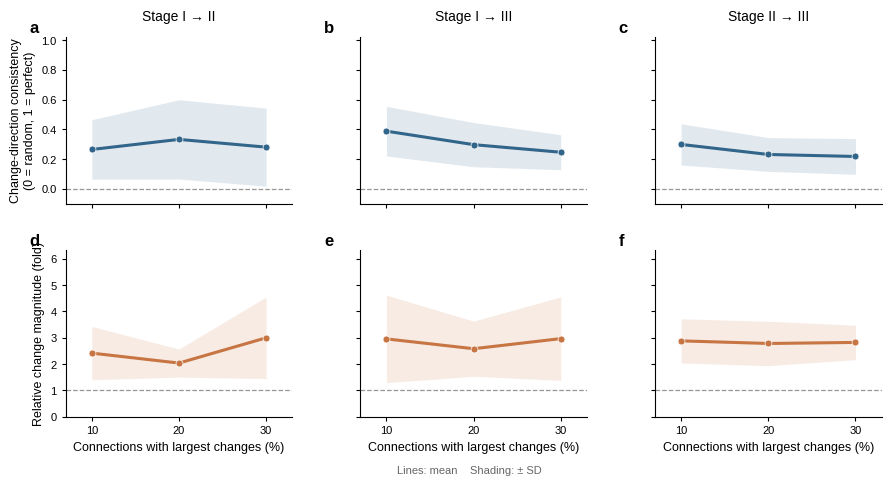

Saved: NEXUS_cross_validated_edge_changes.pdf


In [5]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

seeds = [12,22,32,42,52]
stages = ['stage1','stage2','stage3']
fractions = [10,20,30]
configs = dict(zip(stages,['bs32_dp0.1_sw1.0','bs32_dp0.1_sw1.0','bs32_dp0.1_sw0.5']))
trans = {'II-I':('stage2','stage1'),'III-I':('stage3','stage1'),'III-II':('stage3','stage2')}
titles = {'II-I':'Stage I → II','III-I':'Stage I → III','III-II':'Stage II → III'}
pkl = '../brain_region_wo_layer_{s}_subset{g}_seed{seed}.pkl'
graph = './result_split_seed{seed}/{s}/subset{g}/tuning/{c}/dynamic_full_graphs.npy'
BLUE, ORANGE, GRAY = '#32658A','#C77543','#969696'

sc = pd.read_excel('../SEU_net_wo_corticalLayers.xlsx',header=1,index_col=1).iloc[:,1:]
sc.index = sc.index.astype(str).str.strip()
sc.columns = sc.columns.astype(str).str.strip()

def corr(a,b):
    if len(a)<3 or a.std()==0 or b.std()==0: return np.nan,np.nan
    return np.corrcoef(a,b)[0,1],spearmanr(a,b).statistic

def top(x,k):
    return np.argsort(-np.abs(x),kind='stable')[:k]

def validate(a,b,k):
    idx = top(a,k)
    rest = np.ones(len(a),bool)
    rest[idx] = False
    sa,sb = np.sign(a[idx]),np.sign(b[idx])
    obs = np.mean(sa==sb)
    chance = sum(np.mean(sa==v)*np.mean(np.sign(b)==v) for v in [-1,0,1])
    adj = (obs-chance)/(1-chance) if chance<1 else np.nan
    bg = np.mean(np.abs(b[rest]))
    mag = np.mean(np.abs(b[idx]))/bg if bg>0 else np.nan
    overlap = len(set(idx)&set(top(b,k)))/k
    return obs,chance,adj,mag,overlap

rows,baseline,coverage = [],[],[]

for seed in seeds:
    orders = {}
    for s in stages:
        for g in 'AB':
            with open(pkl.format(seed=seed,s=s,g=g),'rb') as f:
                orders[s,g] = [str(r).strip() for r in pickle.load(f)]

    common = set.intersection(*(set(v) for v in orders.values()))
    regions = [r for r in sc.index if r in common and r in sc.columns]
    S = sc.loc[regions,regions].to_numpy(float)
    mask = np.isfinite(S)&(S!=0)
    np.fill_diagonal(mask,False)
    N = int(mask.sum())
    if N<4: raise ValueError(f'Seed {seed}: insufficient SC edges')
    coverage.append([seed,len(regions),N])

    fc = {}
    for (s,g),order in orders.items():
        path = graph.format(seed=seed,s=s,g=g,c=configs[s])
        x = np.load(path,mmap_mode='r')
        x = x.mean(0) if x.ndim==3 else np.asarray(x)
        if x.shape!=(len(order),len(order)):
            raise ValueError(f'Shape mismatch: {path}')

        csv = f'./result_split_seed{seed}/{s}/subset{g}/df_scaled.csv'
        if os.path.exists(csv):
            actual = pd.read_csv(csv).iloc[:,0].astype(str).str.strip().tolist()
            if actual!=order: raise ValueError(f'Region order mismatch: {csv}')

        index = {r:i for i,r in enumerate(order)}
        ids = [index[r] for r in regions]
        fc[s,g] = x[np.ix_(ids,ids)][mask]
        if not np.isfinite(fc[s,g]).all():
            raise ValueError(f'Non-finite FC: {seed}, {s}, {g}')

    for name,(later,earlier) in trans.items():
        da = fc[later,'A']-fc[earlier,'A']
        db = fc[later,'B']-fc[earlier,'B']
        baseline.append([seed,name,*corr(da,db)])

        for f in fractions:
            k = max(1,int(np.ceil(N*f/100)))
            for direction,a,b in [('A→B',da,db),('B→A',db,da)]:
                rows.append([seed,name,f,direction,k,*validate(a,b,k),k/N])

cols = ['Seed','Transition','Top_pct','Direction','N_selected',
        'Sign_agreement','Chance_sign','Direction_consistency',
        'Relative_magnitude','Top_overlap','Chance_overlap']

cv_df = pd.DataFrame(rows,columns=cols)
baseline_df = pd.DataFrame(baseline,columns=['Seed','Transition','Raw_Pearson','Raw_Spearman'])
seed_df = cv_df.groupby(['Seed','Transition','Top_pct'],as_index=False)[cols[5:]].mean()

display(pd.DataFrame(coverage,columns=['Seed','Regions','SC_edges']))
display(seed_df.groupby(['Transition','Top_pct'])[
    ['Sign_agreement','Chance_sign','Direction_consistency',
     'Relative_magnitude','Top_overlap','Chance_overlap']
].agg(['mean','std']).round(3))
display(seed_df.round(3))
display(baseline_df.round(3))

plt.rcParams.update({
    'font.family':'sans-serif',
    'font.sans-serif':['Arial','Liberation Sans','DejaVu Sans'],
    'font.size':9,'axes.labelsize':9,'axes.titlesize':10,
    'xtick.labelsize':8,'ytick.labelsize':8,
    'axes.linewidth':.8,'xtick.direction':'out','ytick.direction':'out',
    'pdf.fonttype':42,'ps.fonttype':42,
    'pdf.use14corefonts':False,'text.usetex':False
})

fig,axes = plt.subplots(2,3,figsize=(9.6,5.2),sharex=True,sharey='row')
fig.subplots_adjust(left=.13,right=.98,top=.89,bottom=.16,wspace=.30,hspace=.28)

for j,name in enumerate(trans):
    d = seed_df[seed_df.Transition==name]
    for i,(metric,color,ref) in enumerate([
        ('Direction_consistency',BLUE,0),
        ('Relative_magnitude',ORANGE,1)
    ]):
        ax = axes[i,j]

        stat = d.groupby('Top_pct')[metric].agg(['mean','std']).reindex(fractions)
        x = stat.index.to_numpy(float)
        y,sd = stat['mean'].to_numpy(),stat['std'].to_numpy()
        ax.fill_between(x,y-sd,y+sd,color=color,alpha=.14,lw=0)
        ax.plot(x,y,'o-',color=color,lw=2.2,ms=5,
                markeredgecolor='white',markeredgewidth=.5,zorder=5)
        ax.axhline(ref,color=GRAY,ls='--',lw=.9)
        ax.set(xticks=fractions,xlim=(7,33))
        ax.spines[['top','right']].set_visible(False)
        ax.tick_params(length=3,width=.8)
        if i==0: ax.set_title(titles[name],pad=12)
        else: ax.set_xlabel('Connections with largest changes (%)')
        ax.text(-.16,1.10,'abcdef'[i*3+j],transform=ax.transAxes,
                fontsize=12,fontweight='bold',va='top')

axes[0,0].set_ylabel('Change-direction consistency\n(0 = random, 1 = perfect)')
axes[1,0].set_ylabel('Relative change magnitude (fold)')

v = seed_df.Direction_consistency.dropna().to_numpy()
axes[0,0].set_ylim(min(-.1,v.min()-.05) if len(v) else -.1,1.02)

v = seed_df.Relative_magnitude.dropna().to_numpy()
axes[1,0].set_ylim(0,max(1.5,v.max()*1.12) if len(v) else 1.5)

fig.text(.55,.05,'Lines: mean    Shading: ± SD',
         ha='center',fontsize=8,color='#666666')

fig.savefig('NEXUS_cross_validated_edge_changes.pdf',
            format='pdf',bbox_inches='tight',pad_inches=.08,facecolor='white')
plt.show()
print('Saved: NEXUS_cross_validated_edge_changes.pdf')

Seed 12: 32 common regions
Seed 22: 32 common regions
Seed 32: 31 common regions
Seed 42: 30 common regions
Seed 52: 36 common regions


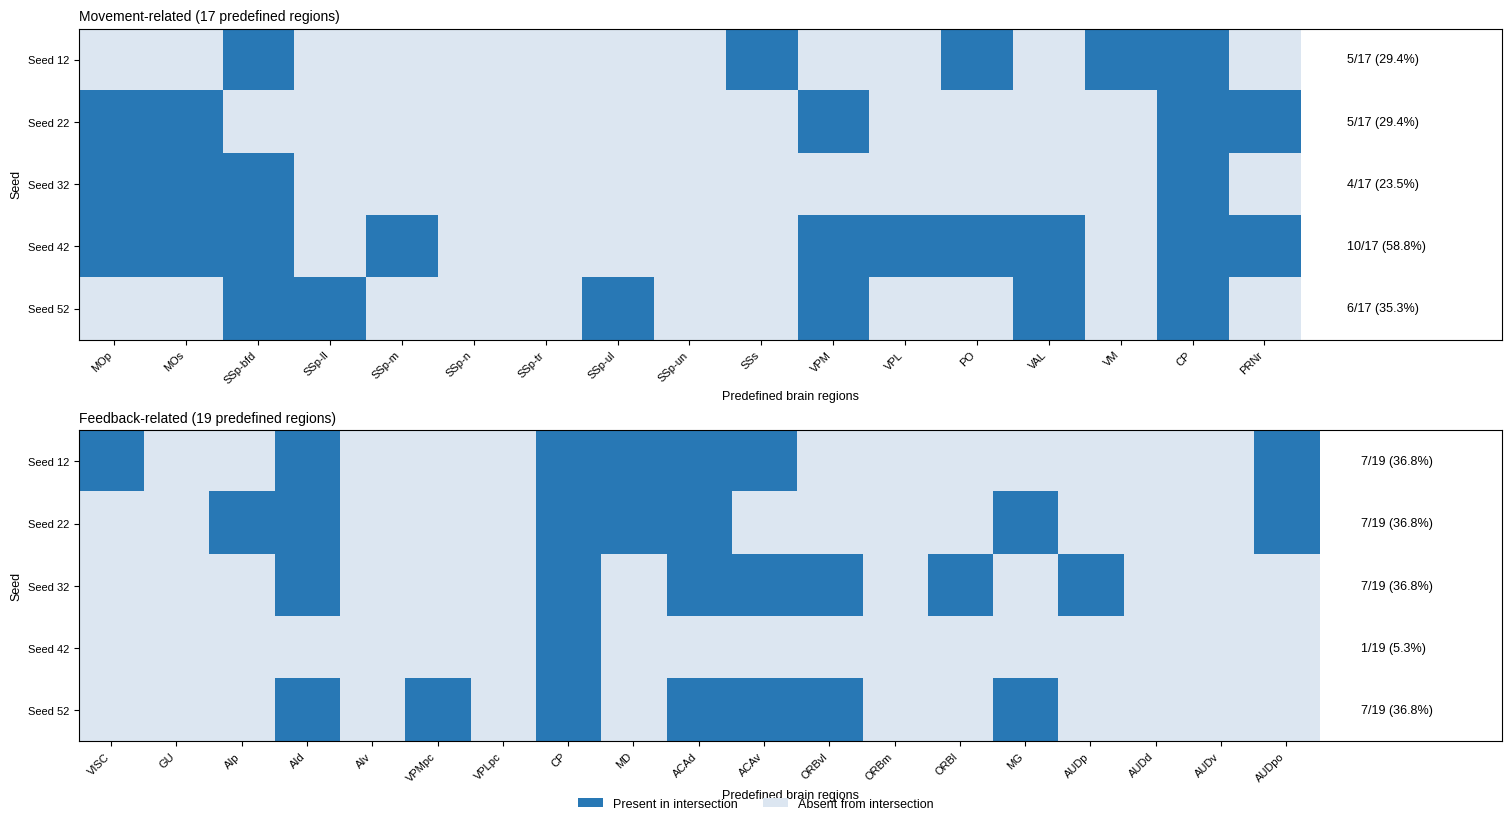

In [6]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

SEEDS = [12, 22, 32, 42, 52]
STAGES = ["stage1", "stage2", "stage3"]
GROUPS = ["A", "B"]

SETS = {
    "Movement-related": [
        "MOp", "MOs", "SSp-bfd", "SSp-ll", "SSp-m", "SSp-n",
        "SSp-tr", "SSp-ul", "SSp-un", "SSs", "VPM", "VPL",
        "PO", "VAL", "VM", "CP", "PRNr"
    ],
    "Feedback-related": [
        "VISC", "GU", "AIp", "AId", "AIv", "VPMpc", "VPLpc",
        "CP", "MD", "ACAd", "ACAv", "ORBvl", "ORBm", "ORBl",
        "MG", "AUDp", "AUDd", "AUDv", "AUDpo"
    ]
}

# Load SC region names
sc = pd.read_excel(
    "../SEU_net_wo_corticalLayers.xlsx",
    header=1, index_col=1
).iloc[:, 1:]

sc.index = sc.index.astype(str).str.strip()
sc.columns = sc.columns.astype(str).str.strip()
sc_regions = set(sc.index) & set(sc.columns)

# Calculate the six-PKL intersection for each seed
covered = {}

for seed in SEEDS:
    region_sets = []

    for stage in STAGES:
        for group in GROUPS:
            path = (
                f"../brain_region_wo_layer_{stage}"
                f"_subset{group}_seed{seed}.pkl"
            )
            with open(path, "rb") as f:
                obj = pickle.load(f)
            region_sets.append({str(r).strip() for r in obj.keys()})

    common = set.intersection(*region_sets) & sc_regions
    covered[seed] = common

    print(f"Seed {seed}: {len(common)} common regions")

# Plot coverage heatmaps
cmap = ListedColormap(["#DCE6F1", "#2878B5"])
fig, axes = plt.subplots(
    2, 1, figsize=(15, 8), constrained_layout=True
)

for ax, (set_name, regions) in zip(axes, SETS.items()):
    mat = np.array([
        [int(r in covered[seed]) for r in regions]
        for seed in SEEDS
    ])

    ax.imshow(
        mat, aspect="auto", interpolation="nearest",
        cmap=cmap, vmin=0, vmax=1
    )

    ax.set_xticks(range(len(regions)))
    ax.set_xticklabels(regions, rotation=45, ha="right")
    ax.set_yticks(range(len(SEEDS)))
    ax.set_yticklabels([f"Seed {s}" for s in SEEDS])
    ax.set_xlabel("Predefined brain regions")
    ax.set_ylabel("Seed")
    ax.set_title(
        f"{set_name} ({len(regions)} predefined regions)",
        loc="left"
    )

    for i in range(len(SEEDS)):
        n = int(mat[i].sum())
        ax.text(
            len(regions) + 0.15, i,
            f"{n}/{len(regions)} ({100*n/len(regions):.1f}%)",
            va="center", ha="left", clip_on=False
        )

    ax.set_xlim(-0.5, len(regions) + 2.3)

fig.legend(
    handles=[
        Patch(facecolor="#2878B5", label="Present in intersection"),
        Patch(facecolor="#DCE6F1", label="Absent from intersection")
    ],
    loc="lower center", ncol=2, frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)

plt.show()